In [3]:
import pulp as plp
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from tqdm import tqdm


In [4]:
L, W = 30, 40

In [5]:
caixas = [(5, 4), (10, 6), (7, 7)]
caixas

[(5, 4), (10, 6), (7, 7)]

In [6]:
qtds_minimas = [4, 4, 1]

In [7]:
ls = []
ws = []
for caixa in caixas:
    ls.append(caixa[0])
    ls.append(caixa[1])
    ws.append(caixa[1])
    ws.append(caixa[0])
arr_ls = np.array(ls)
arr_ws = np.array(ws)
print("arr_ls:", arr_ls)
print("arr_ws:", arr_ws)

arr_ls: [ 5  4 10  6  7  7]
arr_ws: [ 4  5  6 10  7  7]


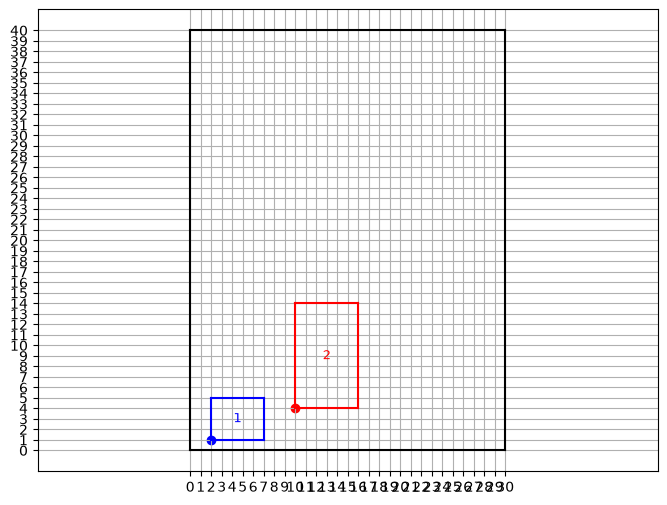

In [8]:
def plotar_caixa(bottom_left: list,
                 l: int,
                 w: int,
                 color: str,
                 label: str):
    x0, y0 = bottom_left
    plt.scatter(x=x0, y=y0, color=color)
    plt.plot([x0, x0 + l], [y0, y0], color=color)
    plt.plot([x0, x0], [y0, y0 + w], color=color)
    plt.plot([x0, x0 + l], [y0 + w, y0 + w], color=color)
    plt.plot([x0 + l, x0 + l], [y0, y0 + w], color=color)
    plt.text(x=x0 + l/2, y=y0 + w/2, s=label, color=color,
             fontsize=9, ha="center", va="center")

def plotar_palete(L: int, W: int, step: int = 1,
                  figsize=(8, 6)):
    plt.figure(figsize=figsize)
    plt.plot([0, L], [0, 0], "k-")
    plt.plot([0, 0], [0, W], "k-")
    plt.plot([0, L], [W, W], "k-")
    plt.plot([L, L], [0, W], "k-")
    plt.xticks(np.arange(0, L + 1, step))
    plt.yticks(np.arange(0, W + 1, step))
    plt.grid()

plotar_palete(L, W, step=1)
plt.axis("equal")
plotar_caixa(bottom_left=[2, 1], l=caixas[0][0], w=caixas[0][1], color="blue", label="1")
plotar_caixa(bottom_left=[10,4], l=caixas[1][1], w=caixas[1][0], color="red", label="2")

In [9]:
f_um = lambda arr_n, arr_l: arr_n @ arr_l
f_dois = lambda arr_n, arr_w: arr_n @ arr_w

In [10]:
menor_lado = min(caixas, key=lambda x: x[1])[1]
menor_lado

4

In [11]:
H = []
for ns in tqdm(product(*[list(range(L)) for _ in range(2 * len(caixas))]), total=(L ** (2 * len(caixas)))):
    arr_ns = np.array(ns)
    p = f_um(arr_n=arr_ns, arr_l=arr_ls)
    if p <= L - menor_lado:
        if p not in H:
            H.append(int(p))

H = sorted(H)
H


100%|██████████| 729000000/729000000 [1:08:16<00:00, 177944.71it/s]


[0,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26]

In [12]:
V = []
for ns in tqdm(product(*[list(range(L)) for _ in range(2 * len(caixas))]), total=(L ** (2 * len(caixas)))):

    arr_ns = np.array(ns)

    q = f_dois(arr_n=arr_ns, arr_w=arr_ws)
    # print(n_um, n_dois, q)
    if q <= W - menor_lado:

        if q not in V:
            V.append(int(q))

V = sorted(V)
V

100%|██████████| 729000000/729000000 [1:05:34<00:00, 185303.01it/s]


[0,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30,
 31,
 32,
 33,
 34,
 35,
 36]

In [13]:
lista_rs = list(product(H, V))
display(lista_rs)

[(0, 0),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 9),
 (0, 10),
 (0, 11),
 (0, 12),
 (0, 13),
 (0, 14),
 (0, 15),
 (0, 16),
 (0, 17),
 (0, 18),
 (0, 19),
 (0, 20),
 (0, 21),
 (0, 22),
 (0, 23),
 (0, 24),
 (0, 25),
 (0, 26),
 (0, 27),
 (0, 28),
 (0, 29),
 (0, 30),
 (0, 31),
 (0, 32),
 (0, 33),
 (0, 34),
 (0, 35),
 (0, 36),
 (4, 0),
 (4, 4),
 (4, 5),
 (4, 6),
 (4, 7),
 (4, 8),
 (4, 9),
 (4, 10),
 (4, 11),
 (4, 12),
 (4, 13),
 (4, 14),
 (4, 15),
 (4, 16),
 (4, 17),
 (4, 18),
 (4, 19),
 (4, 20),
 (4, 21),
 (4, 22),
 (4, 23),
 (4, 24),
 (4, 25),
 (4, 26),
 (4, 27),
 (4, 28),
 (4, 29),
 (4, 30),
 (4, 31),
 (4, 32),
 (4, 33),
 (4, 34),
 (4, 35),
 (4, 36),
 (5, 0),
 (5, 4),
 (5, 5),
 (5, 6),
 (5, 7),
 (5, 8),
 (5, 9),
 (5, 10),
 (5, 11),
 (5, 12),
 (5, 13),
 (5, 14),
 (5, 15),
 (5, 16),
 (5, 17),
 (5, 18),
 (5, 19),
 (5, 20),
 (5, 21),
 (5, 22),
 (5, 23),
 (5, 24),
 (5, 25),
 (5, 26),
 (5, 27),
 (5, 28),
 (5, 29),
 (5, 30),
 (5, 31),
 (5, 32),
 (5, 33),
 (5, 34),
 (5, 35),
 (5, 36),
 

In [14]:
lista_variaveis = []
for (p, q), i, id_caixa in product(lista_rs, [1, 2], range(len(caixas))):
    ls = [caixas[id_caixa][0], caixas[id_caixa][1]]
    ws = [caixas[id_caixa][1], caixas[id_caixa][0]]

    if p + ls[i-1] <= L and q + ws[i-1] <= W: # checa se cabe no palete
        lista_variaveis.append((id_caixa, i, p, q))
display(lista_variaveis)

[(0, 1, 0, 0),
 (1, 1, 0, 0),
 (2, 1, 0, 0),
 (0, 2, 0, 0),
 (1, 2, 0, 0),
 (2, 2, 0, 0),
 (0, 1, 0, 4),
 (1, 1, 0, 4),
 (2, 1, 0, 4),
 (0, 2, 0, 4),
 (1, 2, 0, 4),
 (2, 2, 0, 4),
 (0, 1, 0, 5),
 (1, 1, 0, 5),
 (2, 1, 0, 5),
 (0, 2, 0, 5),
 (1, 2, 0, 5),
 (2, 2, 0, 5),
 (0, 1, 0, 6),
 (1, 1, 0, 6),
 (2, 1, 0, 6),
 (0, 2, 0, 6),
 (1, 2, 0, 6),
 (2, 2, 0, 6),
 (0, 1, 0, 7),
 (1, 1, 0, 7),
 (2, 1, 0, 7),
 (0, 2, 0, 7),
 (1, 2, 0, 7),
 (2, 2, 0, 7),
 (0, 1, 0, 8),
 (1, 1, 0, 8),
 (2, 1, 0, 8),
 (0, 2, 0, 8),
 (1, 2, 0, 8),
 (2, 2, 0, 8),
 (0, 1, 0, 9),
 (1, 1, 0, 9),
 (2, 1, 0, 9),
 (0, 2, 0, 9),
 (1, 2, 0, 9),
 (2, 2, 0, 9),
 (0, 1, 0, 10),
 (1, 1, 0, 10),
 (2, 1, 0, 10),
 (0, 2, 0, 10),
 (1, 2, 0, 10),
 (2, 2, 0, 10),
 (0, 1, 0, 11),
 (1, 1, 0, 11),
 (2, 1, 0, 11),
 (0, 2, 0, 11),
 (1, 2, 0, 11),
 (2, 2, 0, 11),
 (0, 1, 0, 12),
 (1, 1, 0, 12),
 (2, 1, 0, 12),
 (0, 2, 0, 12),
 (1, 2, 0, 12),
 (2, 2, 0, 12),
 (0, 1, 0, 13),
 (1, 1, 0, 13),
 (2, 1, 0, 13),
 (0, 2, 0, 13),
 (1, 2, 0, 13),
 (

In [15]:
prob = plp.LpProblem(name="Palete-Caixa",
                     sense=plp.LpMaximize)
display(prob)

Palete-Caixa:
MAXIMIZE
None
VARIABLES

In [16]:
dict_variaveis = plp.LpVariable.dicts(name="C", indices=lista_variaveis,
                                      lowBound=0, upBound=1,
                                      cat=plp.LpBinary)
display(dict_variaveis)

{(0, 1, 0, 0): C_(0,_1,_0,_0),
 (1, 1, 0, 0): C_(1,_1,_0,_0),
 (2, 1, 0, 0): C_(2,_1,_0,_0),
 (0, 2, 0, 0): C_(0,_2,_0,_0),
 (1, 2, 0, 0): C_(1,_2,_0,_0),
 (2, 2, 0, 0): C_(2,_2,_0,_0),
 (0, 1, 0, 4): C_(0,_1,_0,_4),
 (1, 1, 0, 4): C_(1,_1,_0,_4),
 (2, 1, 0, 4): C_(2,_1,_0,_4),
 (0, 2, 0, 4): C_(0,_2,_0,_4),
 (1, 2, 0, 4): C_(1,_2,_0,_4),
 (2, 2, 0, 4): C_(2,_2,_0,_4),
 (0, 1, 0, 5): C_(0,_1,_0,_5),
 (1, 1, 0, 5): C_(1,_1,_0,_5),
 (2, 1, 0, 5): C_(2,_1,_0,_5),
 (0, 2, 0, 5): C_(0,_2,_0,_5),
 (1, 2, 0, 5): C_(1,_2,_0,_5),
 (2, 2, 0, 5): C_(2,_2,_0,_5),
 (0, 1, 0, 6): C_(0,_1,_0,_6),
 (1, 1, 0, 6): C_(1,_1,_0,_6),
 (2, 1, 0, 6): C_(2,_1,_0,_6),
 (0, 2, 0, 6): C_(0,_2,_0,_6),
 (1, 2, 0, 6): C_(1,_2,_0,_6),
 (2, 2, 0, 6): C_(2,_2,_0,_6),
 (0, 1, 0, 7): C_(0,_1,_0,_7),
 (1, 1, 0, 7): C_(1,_1,_0,_7),
 (2, 1, 0, 7): C_(2,_1,_0,_7),
 (0, 2, 0, 7): C_(0,_2,_0,_7),
 (1, 2, 0, 7): C_(1,_2,_0,_7),
 (2, 2, 0, 7): C_(2,_2,_0,_7),
 (0, 1, 0, 8): C_(0,_1,_0,_8),
 (1, 1, 0, 8): C_(1,_1,_0,_8),
 (2, 1, 

In [17]:
# dict_variaveis.values()
prob += sum(dict_variaveis.values())
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(0,_1,_0,_0) + 1*C_(0,_1,_0,_10) + 1*C_(0,_1,_0,_11) + 1*C_(0,_1,_0,_12) + 1*C_(0,_1,_0,_13) + 1*C_(0,_1,_0,_14) + 1*C_(0,_1,_0,_15) + 1*C_(0,_1,_0,_16) + 1*C_(0,_1,_0,_17) + 1*C_(0,_1,_0,_18) + 1*C_(0,_1,_0,_19) + 1*C_(0,_1,_0,_20) + 1*C_(0,_1,_0,_21) + 1*C_(0,_1,_0,_22) + 1*C_(0,_1,_0,_23) + 1*C_(0,_1,_0,_24) + 1*C_(0,_1,_0,_25) + 1*C_(0,_1,_0,_26) + 1*C_(0,_1,_0,_27) + 1*C_(0,_1,_0,_28) + 1*C_(0,_1,_0,_29) + 1*C_(0,_1,_0,_30) + 1*C_(0,_1,_0,_31) + 1*C_(0,_1,_0,_32) + 1*C_(0,_1,_0,_33) + 1*C_(0,_1,_0,_34) + 1*C_(0,_1,_0,_35) + 1*C_(0,_1,_0,_36) + 1*C_(0,_1,_0,_4) + 1*C_(0,_1,_0,_5) + 1*C_(0,_1,_0,_6) + 1*C_(0,_1,_0,_7) + 1*C_(0,_1,_0,_8) + 1*C_(0,_1,_0,_9) + 1*C_(0,_1,_10,_0) + 1*C_(0,_1,_10,_10) + 1*C_(0,_1,_10,_11) + 1*C_(0,_1,_10,_12) + 1*C_(0,_1,_10,_13) + 1*C_(0,_1,_10,_14) + 1*C_(0,_1,_10,_15) + 1*C_(0,_1,_10,_16) + 1*C_(0,_1,_10,_17) + 1*C_(0,_1,_10,_18) + 1*C_(0,_1,_10,_19) + 1*C_(0,_1,_10,_20) + 1*C_(0,_1,_10,_21) + 1*C_(0,_1,_10,_22) + 1*C_(0,_1,_

In [18]:
print(f"Qtd variaveis: {prob.numVariables()}")
print(f"Qtd restricoes: {prob.numConstraints()}")

Qtd variaveis: 4068
Qtd restricoes: 0


In [19]:
def ponto_dentro_caixa(ponto_rs: tuple,
                       ponto_pq: tuple,
                       l: int, w: int) -> bool:
    r, s = ponto_rs
    p, q = ponto_pq
    return p <= r < p + l and q <= s < q + w
print(ponto_dentro_caixa((6, 2),
                         (6, 0),
                         l=ls[0], w=ws[0]))

True


In [20]:
n = 0
for r, s in lista_rs:
    caixas_sobrepostas = []
    for id_caixa, i, p, q in lista_variaveis:
        ls = [caixas[id_caixa][0], caixas[id_caixa][1]]
        ws = [caixas[id_caixa][1], caixas[id_caixa][0]]

        if ponto_dentro_caixa((r, s),
                              (p, q),
                              l=ls[i-1], w=ws[i-1]):

            caixas_sobrepostas.append(dict_variaveis[(id_caixa, i, p, q)])

    prob += sum(caixas_sobrepostas) <= 1, f"Restricao_1.{n}"
    n += 1
display(prob)

Palete-Caixa:
MAXIMIZE
1*C_(0,_1,_0,_0) + 1*C_(0,_1,_0,_10) + 1*C_(0,_1,_0,_11) + 1*C_(0,_1,_0,_12) + 1*C_(0,_1,_0,_13) + 1*C_(0,_1,_0,_14) + 1*C_(0,_1,_0,_15) + 1*C_(0,_1,_0,_16) + 1*C_(0,_1,_0,_17) + 1*C_(0,_1,_0,_18) + 1*C_(0,_1,_0,_19) + 1*C_(0,_1,_0,_20) + 1*C_(0,_1,_0,_21) + 1*C_(0,_1,_0,_22) + 1*C_(0,_1,_0,_23) + 1*C_(0,_1,_0,_24) + 1*C_(0,_1,_0,_25) + 1*C_(0,_1,_0,_26) + 1*C_(0,_1,_0,_27) + 1*C_(0,_1,_0,_28) + 1*C_(0,_1,_0,_29) + 1*C_(0,_1,_0,_30) + 1*C_(0,_1,_0,_31) + 1*C_(0,_1,_0,_32) + 1*C_(0,_1,_0,_33) + 1*C_(0,_1,_0,_34) + 1*C_(0,_1,_0,_35) + 1*C_(0,_1,_0,_36) + 1*C_(0,_1,_0,_4) + 1*C_(0,_1,_0,_5) + 1*C_(0,_1,_0,_6) + 1*C_(0,_1,_0,_7) + 1*C_(0,_1,_0,_8) + 1*C_(0,_1,_0,_9) + 1*C_(0,_1,_10,_0) + 1*C_(0,_1,_10,_10) + 1*C_(0,_1,_10,_11) + 1*C_(0,_1,_10,_12) + 1*C_(0,_1,_10,_13) + 1*C_(0,_1,_10,_14) + 1*C_(0,_1,_10,_15) + 1*C_(0,_1,_10,_16) + 1*C_(0,_1,_10,_17) + 1*C_(0,_1,_10,_18) + 1*C_(0,_1,_10,_19) + 1*C_(0,_1,_10,_20) + 1*C_(0,_1,_10,_21) + 1*C_(0,_1,_10,_22) + 1*C_(0,_1,_

In [21]:
print(prob.numVariables())
print(prob.numConstraints())

4068
816


In [22]:
for idx, qtd_minima in enumerate(qtds_minimas):
    prob += sum([dict_variaveis[(id_caixa, i, p, q)] 
                 for id_caixa, i, p, q in lista_variaveis 
                 if id_caixa == idx]) >= qtd_minima, f"Restricao_2.{idx}"
prob

Palete-Caixa:
MAXIMIZE
1*C_(0,_1,_0,_0) + 1*C_(0,_1,_0,_10) + 1*C_(0,_1,_0,_11) + 1*C_(0,_1,_0,_12) + 1*C_(0,_1,_0,_13) + 1*C_(0,_1,_0,_14) + 1*C_(0,_1,_0,_15) + 1*C_(0,_1,_0,_16) + 1*C_(0,_1,_0,_17) + 1*C_(0,_1,_0,_18) + 1*C_(0,_1,_0,_19) + 1*C_(0,_1,_0,_20) + 1*C_(0,_1,_0,_21) + 1*C_(0,_1,_0,_22) + 1*C_(0,_1,_0,_23) + 1*C_(0,_1,_0,_24) + 1*C_(0,_1,_0,_25) + 1*C_(0,_1,_0,_26) + 1*C_(0,_1,_0,_27) + 1*C_(0,_1,_0,_28) + 1*C_(0,_1,_0,_29) + 1*C_(0,_1,_0,_30) + 1*C_(0,_1,_0,_31) + 1*C_(0,_1,_0,_32) + 1*C_(0,_1,_0,_33) + 1*C_(0,_1,_0,_34) + 1*C_(0,_1,_0,_35) + 1*C_(0,_1,_0,_36) + 1*C_(0,_1,_0,_4) + 1*C_(0,_1,_0,_5) + 1*C_(0,_1,_0,_6) + 1*C_(0,_1,_0,_7) + 1*C_(0,_1,_0,_8) + 1*C_(0,_1,_0,_9) + 1*C_(0,_1,_10,_0) + 1*C_(0,_1,_10,_10) + 1*C_(0,_1,_10,_11) + 1*C_(0,_1,_10,_12) + 1*C_(0,_1,_10,_13) + 1*C_(0,_1,_10,_14) + 1*C_(0,_1,_10,_15) + 1*C_(0,_1,_10,_16) + 1*C_(0,_1,_10,_17) + 1*C_(0,_1,_10,_18) + 1*C_(0,_1,_10,_19) + 1*C_(0,_1,_10,_20) + 1*C_(0,_1,_10,_21) + 1*C_(0,_1,_10,_22) + 1*C_(0,_1,_

In [23]:
print(prob.numVariables())
print(prob.numConstraints())

4068
819


In [24]:
plp.listSolvers(onlyAvailable=True)

['PULP_CBC_CMD']

In [25]:
solver = plp.getSolver("PULP_CBC_CMD", timeLimit=None)
prob.solve(solver)
print(f"Status: {plp.LpStatus[prob.status]}")

Status: Optimal


In [26]:
print(prob.objective.value())

50.0


In [27]:
dict_traducao = \
    dict(zip(dict_variaveis.values(), 
            dict_variaveis.keys()))
display(dict_traducao)

{C_(0,_1,_0,_0): (0, 1, 0, 0),
 C_(1,_1,_0,_0): (1, 1, 0, 0),
 C_(2,_1,_0,_0): (2, 1, 0, 0),
 C_(0,_2,_0,_0): (0, 2, 0, 0),
 C_(1,_2,_0,_0): (1, 2, 0, 0),
 C_(2,_2,_0,_0): (2, 2, 0, 0),
 C_(0,_1,_0,_4): (0, 1, 0, 4),
 C_(1,_1,_0,_4): (1, 1, 0, 4),
 C_(2,_1,_0,_4): (2, 1, 0, 4),
 C_(0,_2,_0,_4): (0, 2, 0, 4),
 C_(1,_2,_0,_4): (1, 2, 0, 4),
 C_(2,_2,_0,_4): (2, 2, 0, 4),
 C_(0,_1,_0,_5): (0, 1, 0, 5),
 C_(1,_1,_0,_5): (1, 1, 0, 5),
 C_(2,_1,_0,_5): (2, 1, 0, 5),
 C_(0,_2,_0,_5): (0, 2, 0, 5),
 C_(1,_2,_0,_5): (1, 2, 0, 5),
 C_(2,_2,_0,_5): (2, 2, 0, 5),
 C_(0,_1,_0,_6): (0, 1, 0, 6),
 C_(1,_1,_0,_6): (1, 1, 0, 6),
 C_(2,_1,_0,_6): (2, 1, 0, 6),
 C_(0,_2,_0,_6): (0, 2, 0, 6),
 C_(1,_2,_0,_6): (1, 2, 0, 6),
 C_(2,_2,_0,_6): (2, 2, 0, 6),
 C_(0,_1,_0,_7): (0, 1, 0, 7),
 C_(1,_1,_0,_7): (1, 1, 0, 7),
 C_(2,_1,_0,_7): (2, 1, 0, 7),
 C_(0,_2,_0,_7): (0, 2, 0, 7),
 C_(1,_2,_0,_7): (1, 2, 0, 7),
 C_(2,_2,_0,_7): (2, 2, 0, 7),
 C_(0,_1,_0,_8): (0, 1, 0, 8),
 C_(1,_1,_0,_8): (1, 1, 0, 8),
 C_(2,_1

In [28]:
variaveis_organizadas = []
for variavel in prob.variables():
    # print(variavel.name, variavel.varValue)
    if variavel.varValue > 0:
        var_traduzida = dict_traducao[variavel]
        variaveis_organizadas.append(var_traduzida)
display(variaveis_organizadas)

[(0, 1, 0, 22),
 (0, 1, 0, 26),
 (0, 1, 10, 20),
 (0, 1, 10, 24),
 (0, 1, 10, 28),
 (0, 1, 11, 32),
 (0, 1, 11, 36),
 (0, 1, 15, 10),
 (0, 1, 15, 14),
 (0, 1, 15, 18),
 (0, 1, 15, 22),
 (0, 1, 16, 32),
 (0, 1, 16, 36),
 (0, 1, 20, 10),
 (0, 1, 20, 14),
 (0, 1, 20, 18),
 (0, 1, 20, 22),
 (0, 1, 21, 32),
 (0, 1, 21, 36),
 (0, 1, 25, 10),
 (0, 1, 25, 14),
 (0, 1, 25, 18),
 (0, 1, 25, 22),
 (0, 1, 25, 26),
 (0, 1, 5, 25),
 (0, 1, 5, 29),
 (0, 1, 6, 12),
 (0, 1, 6, 16),
 (0, 2, 0, 30),
 (0, 2, 0, 35),
 (0, 2, 10, 0),
 (0, 2, 10, 5),
 (0, 2, 11, 10),
 (0, 2, 11, 15),
 (0, 2, 14, 0),
 (0, 2, 14, 5),
 (0, 2, 18, 0),
 (0, 2, 18, 5),
 (0, 2, 22, 0),
 (0, 2, 22, 5),
 (0, 2, 26, 0),
 (0, 2, 26, 30),
 (0, 2, 26, 35),
 (0, 2, 26, 5),
 (0, 2, 6, 20),
 (1, 1, 0, 0),
 (1, 1, 0, 6),
 (1, 1, 15, 26),
 (1, 2, 0, 12),
 (2, 2, 4, 33)]

In [29]:
variaveis_organizadas = sorted(variaveis_organizadas,
                               key=lambda x: (x[2], x[3]))

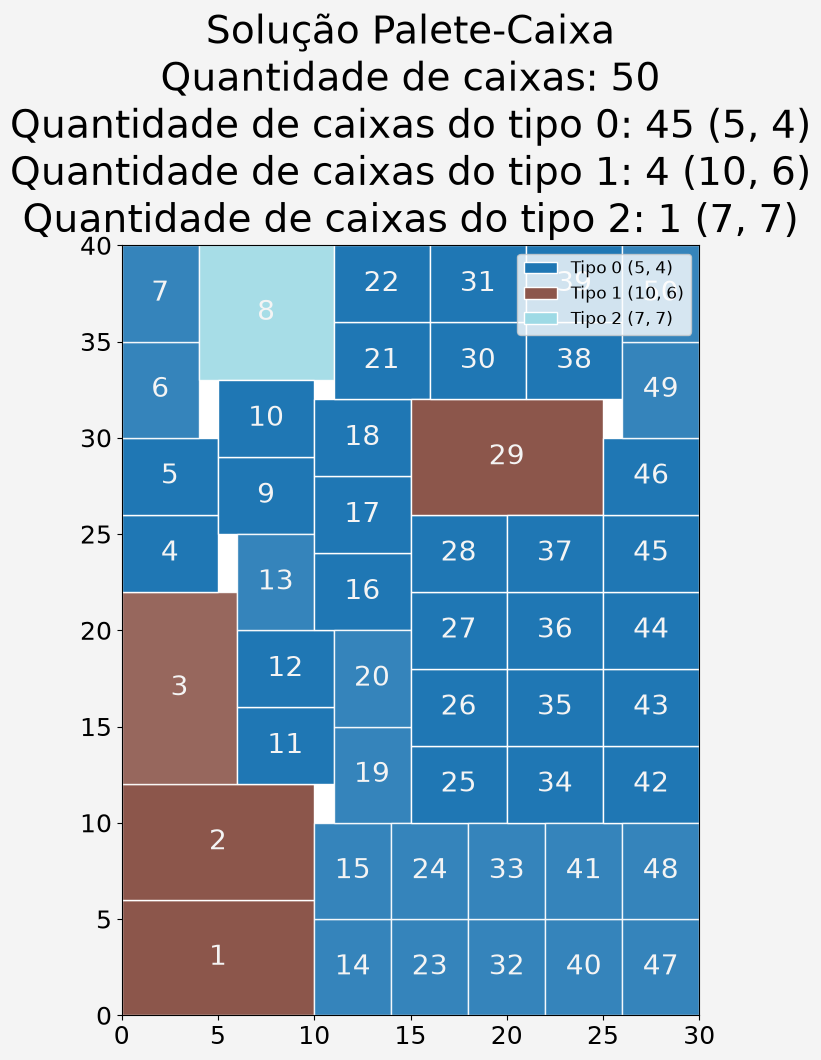

In [30]:
if plp.LpStatus[prob.status] == "Optimal":
    fig, ax = plt.subplots(figsize=(10, 10))
    fig.set_facecolor('#f4f4f4')

    # a = plt.gca()
    # a.set_xticks(list(range(0, L + 1, l_um)) + [L])
    # a.set_yticks(list(range(0, W + 1, w_um)) + [W])
    # a.set_xticklabels(a.get_xticks())
    # a.set_yticklabels(a.get_yticks())

    qtd_caixas = len(variaveis_organizadas)
    qtd_caixas_tipo = [len([v for v in variaveis_organizadas if v[0] == i]) for i in range(len(caixas))]

    from matplotlib import colors as mcolors

    cmap = plt.get_cmap("tab20", len(caixas)) if len(caixas) <= 20 else plt.get_cmap("hsv", len(caixas))
    paleta_caixas = {}
    for id_caixa in range(len(caixas)):
        paleta_caixas[id_caixa] = mcolors.to_hex(cmap(id_caixa))

    for indice_caixa, variavel_organizada in enumerate(variaveis_organizadas, 1):
        id_caixa, i, p, q = variavel_organizada

        ls = [caixas[id_caixa][0], caixas[id_caixa][1]]
        ws = [caixas[id_caixa][1], caixas[id_caixa][0]]

        cor = paleta_caixas.get(id_caixa, "#7f7f7f")
        alpha = 1.0 if i == 1 else 0.9

        ax.add_patch(plt.Rectangle(xy=(p, q), 
                                width=ls[i - 1], 
                                height=ws[i - 1], 
                                facecolor=cor, 
                                edgecolor="white", lw=1,
                                alpha=alpha,))

        plt.text(x=p + ls[i - 1] / 2, 
                y=q + ws[i - 1] / 2, 
                s=f"{indice_caixa}", 
                fontsize=20,
                color="#f4f4f4",
                ha="center", 
                va="center")

    texto_qtds_tipo = "\n".join([f"Quantidade de caixas do tipo {i}: {qtd_caixas_tipo[i]} {caixas[i]}" for i in range(len(caixas))])
    ax.set_title(f"Solução Palete-Caixa\nQuantidade de caixas: {qtd_caixas}\n{texto_qtds_tipo}",
                    fontsize=28)


    legend_handles = []
    for id_caixa in range(len(caixas)):
        patch = plt.Rectangle((0, 0), 1, 1, facecolor=paleta_caixas[id_caixa], edgecolor="white", label=f"Tipo {id_caixa} {caixas[id_caixa]}")
        legend_handles.append(patch)

    ax.legend(handles=legend_handles, loc="upper right", frameon=True, fontsize=12)

    ax.set_xlim(0, L)
    ax.set_ylim(0, W)
    ax.set_aspect("equal")

    ax.xaxis.set_tick_params(labelsize=18)
    ax.yaxis.set_tick_params(labelsize=18)
else:
    print(plp.LpStatus[prob.status])